### Practical 4 - NON-NEGATIVE MATRIX FACTORISATION

`Dataset - Movielens Small (mlsmall)`

In [37]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error as mae, mean_squared_error as mse
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
DATA_FOLDER = "/content/drive/MyDrive/mlsmall"
RATINGS_FILE = DATA_FOLDER + "/ratings.csv"
MOVIES_FILE = DATA_FOLDER + "/movies.csv"

N_FACTORS = 10
N_ITERATIONS = 100
EPSILON = 1e-8
TOP_N = 10
RANKING_K = 10
RELEVANCE_THRESHOLD = 4.0
DEMO_USER_ID = 25
TOP_MOVIES_PER_FACTOR = 10
RANDOM_STATE = 19

In [13]:
r = pd.read_csv(RATINGS_FILE)
m = pd.read_csv(MOVIES_FILE).set_index("movieId")

print("MOVIELENS DATASET")
print("=" * 70)
print("Ratings shape:", r.shape)
print("Movies shape :", m.shape)
print("Distinct user Count:", r["userId"].nunique())

display(r.head())
display(m.head())

MOVIELENS DATASET
Ratings shape: (100836, 4)
Movies shape : (9742, 2)
Distinct user Count: 610


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,title,genres
movieId,,
1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
2,Jumanji (1995),Adventure|Children|Fantasy
3,Grumpier Old Men (1995),Comedy|Romance
4,Waiting to Exhale (1995),Comedy|Drama|Romance
5,Father of the Bride Part II (1995),Comedy


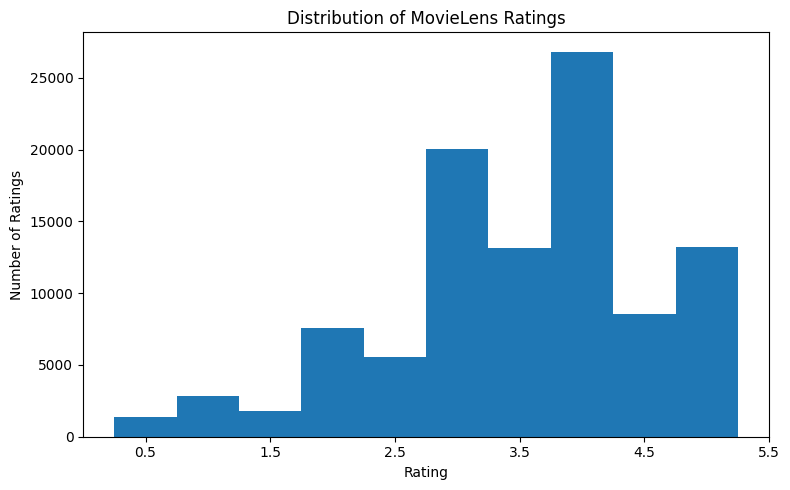

In [26]:
plt.figure(figsize=(8, 5))
plt.hist(r["rating"], bins = np.arange(0.25, 5.75, 0.5))
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.title("Distribution of MovieLens Ratings")
plt.xticks(np.arange(0.5, 5.76, ))
plt.tight_layout()
plt.show()

In [27]:
# chronological split: each user's latest rating -> test
test = r.loc[r.groupby("userId").timestamp.idxmax()]
train = r.drop(test.index)

print("\nTraining ratings:", len(train))
print("Testing ratings :", len(test))


Training ratings: 100226
Testing ratings : 610


In [33]:
# Create user-item matrix
T = train.pivot_table(index="userId", columns="movieId", values="rating")
display(T.iloc[:10, :10])

movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,4.0,5.0,3.0,5.0,4.0,4.0,3.0,NaN,3.0
7,4.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
# Sparsity
observed_count = int(T.notna().sum().sum())
total_cells = T.shape[0] * T.shape[1]
density = observed_count / total_cells
sparsity = 1.0 - density

print(f"\nMatrix density : {density*100:.2f}%")
print(f"Matrix sparsity : {sparsity*100:.2f}%")


Matrix density : 1.69%
Matrix sparsity : 98.31%


In [36]:
# build rating matrix R and observation mask M matrix
R, M = T.fillna(0).values, T.notna().values.astype(float)
print("R shape: ", R.shape)
print("M shape: ", M.shape)

R shape:  (610, 9702)
M shape:  (610, 9702)


In [47]:
# masked NMF (multiplicative updates)
rng = np.random.default_rng(19)
W = rng.random((R.shape[0], 10)) + 0.1 
H = rng.random((10, R.shape[1])) + 0.1
for _ in range(100):
    H *= (W.T @ R) / (W.T @ (M * (W @ H)) + 1e-8)
    W *= (R @ H.T) / ((M * (W @ H)) @ H.T + 1e-8)
P = pd.DataFrame(np.clip(W @ H, .5, 5), T.index, T.columns)

# rating prediction
t = test[test.userId.isin(P.index) & test.movieId.isin(P.columns)]
pred = [P.at[u, i] for u, i in zip(t.userId, t.movieId)]
print("MAE", round(mae(t.rating, pred), 2), 
      "\nRMSE", round(mse(t.rating, pred) ** .5, 2), 
      "\nCoverage", round(len(t) / len(test), 2))

print("W shape:", W.shape)
print("H shape:", H.shape)

MAE 0.83 
RMSE 1.1 
Coverage 0.96
W shape: (610, 10)
H shape: (10, 9702)


In [48]:
# top-N
def recommend(u, n=10):
    s = P.loc[u].drop(T.loc[u].dropna().index).nlargest(n)
    return pd.DataFrame({"Movie": m.title.reindex(s.index).values,
                         "Genres": m.genres.reindex(s.index).values, "Pred": s.values})
print(recommend(25))

                                         Movie                  Genres  Pred
0                                Casino (1995)             Crime|Drama   5.0
1              Cry, the Beloved Country (1995)                   Drama   5.0
2                            To Die For (1995)   Comedy|Drama|Thriller   5.0
3                  Seven (a.k.a. Se7en) (1995)        Mystery|Thriller   5.0
4                   Usual Suspects, The (1995)  Crime|Mystery|Thriller   5.0
5                              Lamerica (1994)         Adventure|Drama   5.0
6                             Nico Icon (1995)             Documentary   5.0
7  White Balloon, The (Badkonake sefid) (1995)          Children|Drama   5.0
8                    Angels and Insects (1995)           Drama|Romance   5.0
9         Heidi Fleiss: Hollywood Madam (1995)             Documentary   5.0


In [51]:
# ranking metrics (relevant = rating >= 4)
rel = t[t.rating >= 4]
ranks = np.array([P.loc[u].drop(T.loc[u].dropna().index).rank(ascending=False)[i]
                  for u, i in zip(rel.userId, rel.movieId)])
k = ranks <= 10
print("Hit@10", k.mean(), "MRR@10", np.where(k, 1 / ranks, 0).mean(),
      "NDCG@10", np.where(k, 1 / np.log2(ranks + 1), 0).mean())

Hit@10 0.0 MRR@10 0.0 NDCG@10 0.0
